# Regression Models in `scikitlearn`

**OBJECTIVES**

- Use `LinearRegression` to build regression models
- Interpret a fit regression models parameters
- Understand the train/test split process
- Use `StandardScaler` to scale features
- Use `OneHotEncoder` to encode categorical features
- Use `Pipeline` to combine transformers and estimators

### The Initial Problem

Below, the dataset from Geron's [Hands on Machine Learning with `scikitlearn` and `pytorch`]() Chapter 2 is loaded.  This dataset represents neighborhoods in California and the task is to predict `median_house_value`. 

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
housing = pd.read_csv('data/housing.csv')

In [3]:
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


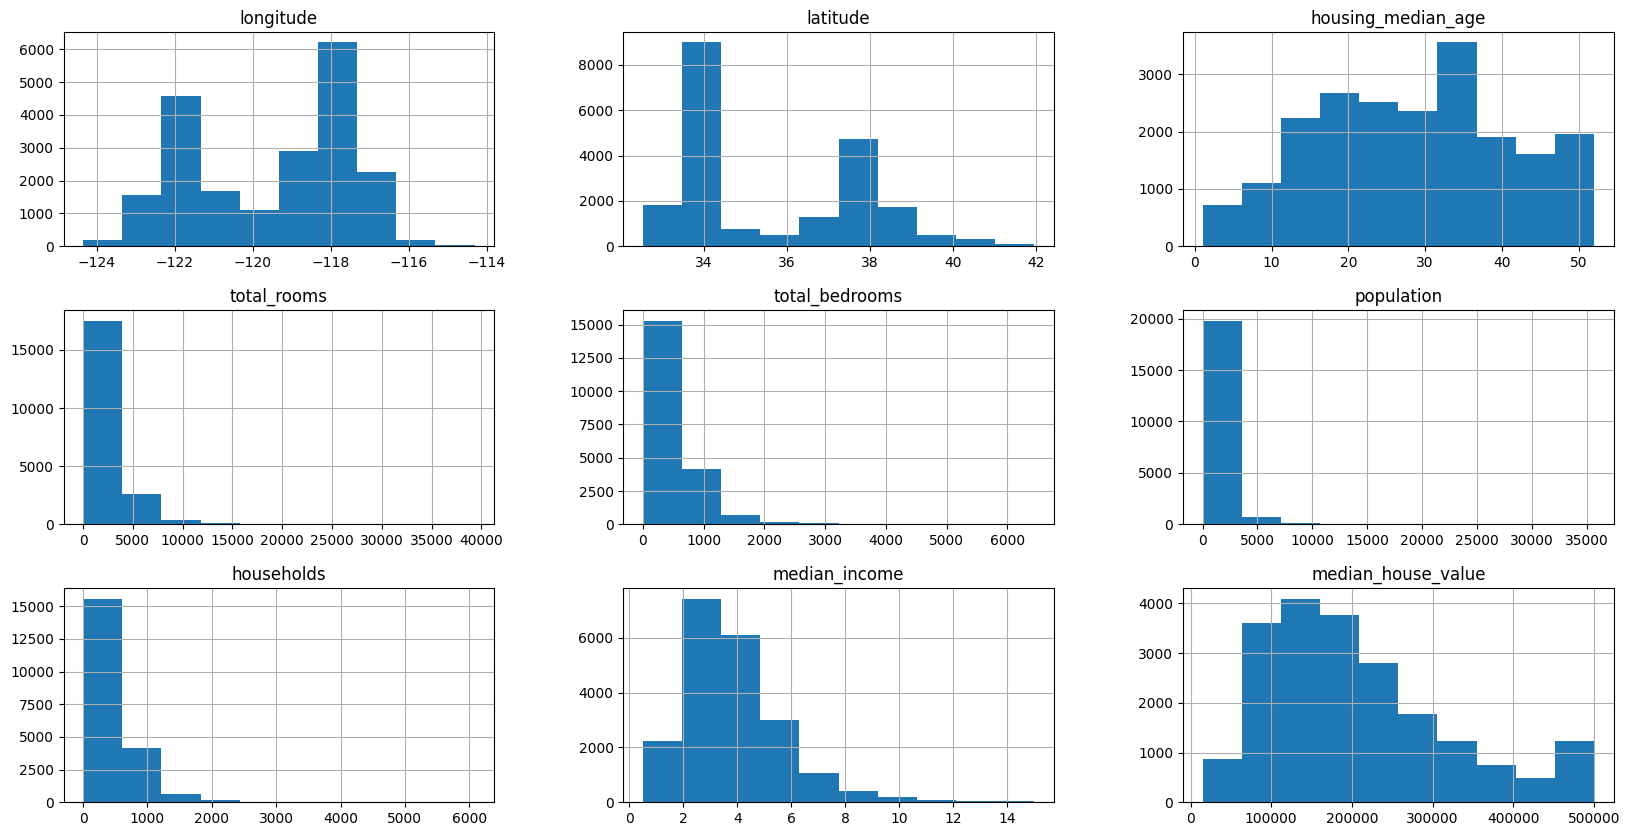

In [6]:
housing.hist(figsize = (20, 10));

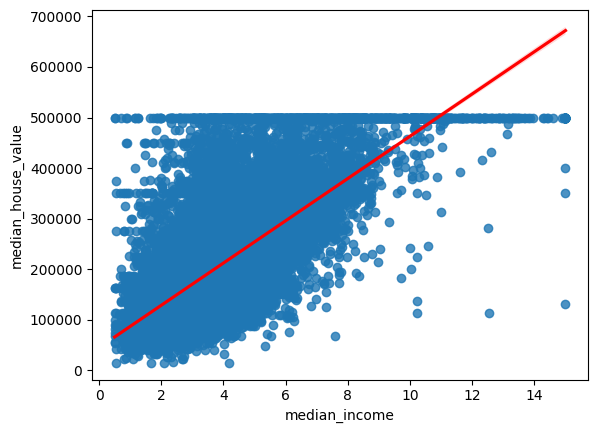

In [12]:
sns.regplot(data = housing, x = 'median_income', y = 'median_house_value', line_kws = {'color': 'red'});

### Regression with `sklearn`

- Create `X` and `y` -- **X MUST BE 2D**
- Instantiate
- Fit
- Predict/Evaluate

In [14]:
from sklearn.linear_model import LinearRegression

In [15]:
X = housing[['median_income']]
y = housing['median_house_value']

In [16]:
#instantiate
lr = LinearRegression()

In [17]:
#fit
lr.fit(X, y)

LinearRegression()

In [18]:
#predict
lr.predict(X)

array([393027.73007889, 392033.03646789, 348400.25790111, ...,
       116135.12034649, 123123.05193305, 144914.36490692])

In [25]:
params = {'slope': lr.coef_[0], 
 'intercept': lr.intercept_}

In [26]:
pd.DataFrame(params, index = ['median_income_model'])

,slope,intercept
median_income_model,41793.849202,45085.576703


### Evaluation Metrics

- Built in $r^2$: $$r^2 = 1 - \frac{RSS}{TSS}$$
- `mean_squared_error`: built in in `sklearn.metrics`
- **RMSE**: root mean squared error -- square root of `mean_squared_error`

In [27]:
#r^2 from scratch
rss = np.sum((lr.predict(X) - y)**2)
tss = np.sum((y - y.mean())**2)

In [28]:
1 - rss/tss

0.47344749180719903

In [29]:
lr.score(X, y)

0.47344749180719903